In [2]:
import pandas as pd
from lmetk.case_studies.file_datamodule import CSVLongTermForecastingModule
from pathlib import Path
from omegaconf import OmegaConf
from hydra import initialize as hydra_initialize, compose
from hydra.utils import instantiate

%reload_ext autoreload
%autoreload 2
%matplotlib inline

torch.Size([32, 24, 6]) torch.Size([32, 24, 1]) torch.Size([32, 24, 6]) torch.Size([32, 24, 1])


array([[<Axes: title={'center': 'u100'}>,
        <Axes: title={'center': 'v100'}>,
        <Axes: title={'center': 'fsr'}>],
       [<Axes: title={'center': 'Windspeed'}>,
        <Axes: title={'center': 'Scaled_Windspeed_(at_123.5m)'}>,
        <Axes: title={'center': 'Wind_Direction'}>],
       [<Axes: title={'center': 'Power'}>, <Axes: >, <Axes: >]],
      dtype=object)

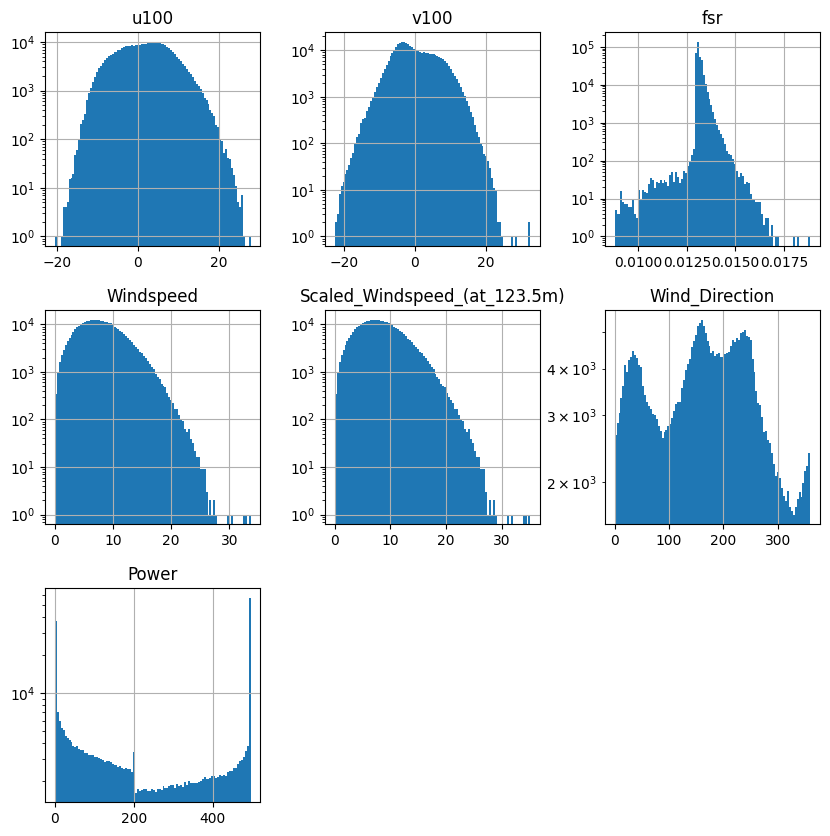

In [3]:

cfg = OmegaConf.load('configs/datamodule/wind_farm.yaml')
dm = instantiate(cfg)
dm.setup()
type(dm)
dl = dm.train_dataloader()
batch = next(iter(dl))
print(batch[0].shape, batch[1].shape, batch[2].shape, batch[3].shape)
dm.data.hist(log=True, bins=100, figsize=(10, 10))

In [4]:
lag = 12
X_train, y_train =  dm.to_sklearn(dl=dm.train_dataloader(), lag=lag)    
X_test, y_test =  dm.to_sklearn(dl=dm.test_dataloader(), lag=lag)

In [5]:
X_test.shape

(35017, 30)

In [6]:
import numpy as np
from einops import rearrange

cfg = OmegaConf.load('configs/model/tabpfn.yaml')
tpfn = instantiate(cfg)


In [22]:


W = 100
N = 100
N_test = 100
X_windows = []
for i in range(0, len(X_train) - W + 1, N):
    
    tpfn = instantiate(cfg)
    
    X_w = X_train[i:i+W]
    y_w = y_train[i:i+W]
    print(X_w.shape, y_w.shape) 
    tpfn.fit(X_w, y_w)
    
    preds = rearrange(tpfn.predict(X_test[:N_test])
                      , "N -> N 1")
    
    out_dict = tpfn.predict(X_test[:N_test], output_type='full')
    
    print(preds.shape)
    break

(100, 30) (100, 1)


c:\Users\Raffael\miniforge3\envs\torch2_cuda12.1\lib\site-packages\sklearn\utils\validation.py:1300: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
C:\Users\Raffael\Documents\Workspaces\work\load_management_evaluation\TabPFN\src\tabpfn\model\multi_head_attention.py:710: UserWarning: 1Torch was not compiled with flash attention. (Triggered internally at C:\cb\pytorch_1000000000000\work\aten\src\ATen\native\transformers\cuda\sdp_utils.cpp:252.)
  attention_head_outputs = torch.nn.functional.scaled_dot_product_attention(
C:\Users\Raffael\Documents\Workspaces\work\load_management_evaluation\TabPFN\src\tabpfn\model\multi_head_attention.py:710: UserWarning: 1Torch was not compiled with flash attention. (Triggered internally at C:\cb\pytorch_1000000000000\work\aten\src\ATen\native\transformers\cuda\sdp_utils.cpp:252.)
  attention_head_outputs = torch.nn

(100, 1)


C:\Users\Raffael\Documents\Workspaces\work\load_management_evaluation\TabPFN\src\tabpfn\model\multi_head_attention.py:710: UserWarning: 1Torch was not compiled with flash attention. (Triggered internally at C:\cb\pytorch_1000000000000\work\aten\src\ATen\native\transformers\cuda\sdp_utils.cpp:252.)
  attention_head_outputs = torch.nn.functional.scaled_dot_product_attention(


In [28]:
from tabpfn.utils import validate_X_predict, _fix_dtypes
import torch
import einops

single_eval_pos_ = 0


X = validate_X_predict(X_w, tpfn)
X = _fix_dtypes(X, cat_indices=tpfn.categorical_features_indices)
X = tpfn.preprocessor_.transform(X)

tmodel = tpfn.executor_.model


X = tpfn.executor_.preprocessors[0].transform(X).X # _TransformResult
X = torch.as_tensor(X, dtype=torch.float32, device="cpu").unsqueeze(1)

x = {"main": X}
seq_len, batch_size, num_features = x["main"].shape
for k in x:
    num_features_ = x[k].shape[2]

    # pad to multiple of features_per_group
    missing_to_next = (
        tmodel.features_per_group - (num_features_ % tmodel.features_per_group)
    ) % tmodel.features_per_group

    if missing_to_next > 0:
        x[k] = torch.cat(
            (
                x[k],
                torch.zeros(
                    seq_len,
                    batch_size,
                    missing_to_next,
                    device=x[k].device,
                    dtype=x[k].dtype,
                ),
            ),
            dim=-1,
        )

for k in x:
    x[k] = einops.rearrange(
        x[k],
        "s b (f n) -> b s f n",
        n=tmodel.features_per_group,
    )  # s b f -> b s #groups #features_per_group

extra_encoders_args = {}
for k in x:
    x[k] = einops.rearrange(x[k], "b s f n -> s (b f) n")
print(x["main"].shape)
embedded_x = einops.rearrange(tmodel.encoder(
    x,
    single_eval_pos=single_eval_pos_,
    cache_trainset_representation=tmodel.cache_trainset_representation,
    **extra_encoders_args,
),
    "s (b f) e -> b s f e",
    b=1,
)  # b s f 1 -> b s f e

x["main"].shape, embedded_x.shape

torch.Size([100, 36, 2])


(torch.Size([100, 36, 2]), torch.Size([1, 100, 36, 192]))

In [27]:
tpfn.executor_.preprocessors[0]

SequentialFeatureTransformer([<tabpfn.model.preprocessing.RemoveConstantFeaturesStep at 0x253f82055d0>,
                              <tabpfn.model.preprocessing.ShuffleFeaturesStep at 0x253f8205480>])

In [18]:

for output, config in tpfn.executor_.iter_outputs(
    X,
    device=tpfn.device_,
    autocast=tpfn.use_autocast_,
):
    print(config)

c:\Users\Raffael\miniforge3\envs\torch2_cuda12.1\lib\site-packages\tabpfn\model\multi_head_attention.py:710: UserWarning: 1Torch was not compiled with flash attention. (Triggered internally at C:\cb\pytorch_1000000000000\work\aten\src\ATen\native\transformers\cuda\sdp_utils.cpp:252.)
  attention_head_outputs = torch.nn.functional.scaled_dot_product_attention(
c:\Users\Raffael\miniforge3\envs\torch2_cuda12.1\lib\site-packages\tabpfn\model\multi_head_attention.py:710: UserWarning: 1Torch was not compiled with flash attention. (Triggered internally at C:\cb\pytorch_1000000000000\work\aten\src\ATen\native\transformers\cuda\sdp_utils.cpp:252.)
  attention_head_outputs = torch.nn.functional.scaled_dot_product_attention(
c:\Users\Raffael\miniforge3\envs\torch2_cuda12.1\lib\site-packages\tabpfn\model\multi_head_attention.py:710: UserWarning: 1Torch was not compiled with flash attention. (Triggered internally at C:\cb\pytorch_1000000000000\work\aten\src\ATen\native\transformers\cuda\sdp_utils.c

RegressorEnsembleConfig(preprocess_config=PreprocessorConfig(name='quantile_uni', categorical_name='ordinal_very_common_categories_shuffled', append_original=True, subsample_features=-1, global_transformer_name='svd'), add_fingerprint_feature=True, polynomial_features='no', feature_shift_count=636, feature_shift_decoder='shuffle', subsample_ix=None, target_transform=None)
RegressorEnsembleConfig(preprocess_config=PreprocessorConfig(name='quantile_uni', categorical_name='ordinal_very_common_categories_shuffled', append_original=True, subsample_features=-1, global_transformer_name='svd'), add_fingerprint_feature=True, polynomial_features='no', feature_shift_count=637, feature_shift_decoder='shuffle', subsample_ix=None, target_transform=None)
RegressorEnsembleConfig(preprocess_config=PreprocessorConfig(name='quantile_uni', categorical_name='ordinal_very_common_categories_shuffled', append_original=True, subsample_features=-1, global_transformer_name='svd'), add_fingerprint_feature=True, p

c:\Users\Raffael\miniforge3\envs\torch2_cuda12.1\lib\site-packages\tabpfn\model\multi_head_attention.py:710: UserWarning: 1Torch was not compiled with flash attention. (Triggered internally at C:\cb\pytorch_1000000000000\work\aten\src\ATen\native\transformers\cuda\sdp_utils.cpp:252.)
  attention_head_outputs = torch.nn.functional.scaled_dot_product_attention(
c:\Users\Raffael\miniforge3\envs\torch2_cuda12.1\lib\site-packages\tabpfn\model\multi_head_attention.py:710: UserWarning: 1Torch was not compiled with flash attention. (Triggered internally at C:\cb\pytorch_1000000000000\work\aten\src\ATen\native\transformers\cuda\sdp_utils.cpp:252.)
  attention_head_outputs = torch.nn.functional.scaled_dot_product_attention(
c:\Users\Raffael\miniforge3\envs\torch2_cuda12.1\lib\site-packages\tabpfn\model\multi_head_attention.py:710: UserWarning: 1Torch was not compiled with flash attention. (Triggered internally at C:\cb\pytorch_1000000000000\work\aten\src\ATen\native\transformers\cuda\sdp_utils.c

In [14]:
X

array([[6.04357362e-01, 5.27360380e-01, 4.28500682e-01, ...,
        1.00000000e+00, 1.00000000e+00, 1.00000000e+00],
       [6.15566194e-01, 4.05029833e-01, 4.29990381e-01, ...,
        9.96674299e-01, 1.00000000e+00, 9.95260537e-01],
       [3.93452764e-01, 4.83401895e-01, 4.19820577e-01, ...,
        8.79174948e-01, 9.13013518e-01, 7.75740504e-01],
       ...,
       [5.85557461e-01, 5.06141484e-01, 4.34926748e-01, ...,
        0.00000000e+00, 0.00000000e+00, 3.50884075e-04],
       [4.01173830e-01, 2.38003388e-01, 4.26884472e-01, ...,
        1.00000000e+00, 9.99688506e-01, 1.00000000e+00],
       [6.02947235e-01, 3.67879152e-01, 4.24897879e-01, ...,
        5.81613183e-01, 4.09658939e-01, 5.67288399e-01]])

<Axes: >

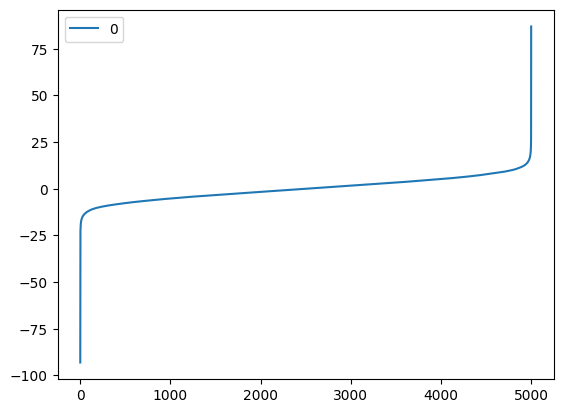

In [56]:
import pandas as pd
pd.DataFrame(tabpfn.bardist_.borders.numpy()).plot()

In [38]:
out_dict.keys()

dict_keys(['criterion', 'logits', 'mean', 'median', 'mode', 'quantiles'])

In [40]:
out_dict['logits'].shape

torch.Size([100, 5000])

In [41]:
out_dict['criterion']

FullSupportBarDistribution()

In [47]:
len(out_dict['quantiles'])

9

In [27]:
from sklearn.preprocessing import QuantileTransformer
import numpy as np

X = np.array([[1], [2], [2], [3], [5]])
qt = QuantileTransformer(n_quantiles=5, output_distribution='normal', random_state=0)
X_trans = qt.fit_transform(X)

print(X_trans)

[[-5.19933758]
 [-0.31863936]
 [-0.31863936]
 [ 0.67448975]
 [ 5.19933758]]


In [25]:
tabpfn.model_.transformer_encoder.layers[0]

PerFeatureEncoderLayer(
  (self_attn_between_features): MultiHeadAttention()
  (self_attn_between_items): MultiHeadAttention()
  (mlp): MLP(
    (linear1): Linear(in_features=192, out_features=768, bias=False)
    (linear2): Linear(in_features=768, out_features=192, bias=False)
  )
  (layer_norms): ModuleList(
    (0-2): 3 x LayerNorm((192,), eps=1e-05, elementwise_affine=False)
  )
)

In [23]:
tabpfn.fit(X_train, y_train)    

c:\Users\Raffael\miniforge3\envs\torch2_cuda12.1\lib\site-packages\sklearn\utils\validation.py:1300: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\Raffael\miniforge3\envs\torch2_cuda12.1\lib\site-packages\tabpfn\regressor.py:426: UserWarning: Number of samples 280465 is greater than the maximum Number of samples 10000 supported by the model. You may see degraded performance.
  X, y, feature_names_in, n_features_in = validate_Xy_fit(


ValueError: The number of quantiles cannot be greater than the number of samples used. Got 56093 quantiles and 10000 samples.

In [ ]:

cfg = OmegaConf.load('configs/datamodule/etth1.yaml')
dm = instantiate(cfg)
dm.setup()
type(dm)
dl = dm.train_dataloader()
batch = next(iter(dl))
print(batch[0].shape, batch[1].shape, batch[2].shape, batch[3].shape)

train 8449
test 2785
val 2785
torch.Size([32, 96, 7]) torch.Size([32, 96, 7]) torch.Size([32, 96, 4]) torch.Size([32, 96, 4])


In [34]:
batch = next(iter(dm.train_dataloader()))
X, y = dm.to_sklearn(dm.train_dataloader())    

In [35]:
X.shape, y.shape

((8449, 676), (8449,))

In [36]:
batch[0].shape, batch[1].shape, batch[2].shape, batch[3].shape

(torch.Size([32, 96, 7]),
 torch.Size([32, 96, 7]),
 torch.Size([32, 96, 4]),
 torch.Size([32, 96, 4]))

In [ ]:
import numpy as np
import time
from sklearn.preprocessing import QuantileTransformer

def test_quantile_transformer_speed():
    # Use a dataset with many samples so that default subsampling is active.
    n_samples = 200_000  # more than the default subsample limit (typically 100000)
    n_features = 100
    n_quantiles = 10_000
    X = np.random.rand(n_samples, n_features)

    n_runs = 5
    default_times = []
    large_times = []

    for run in range(n_runs):
        print(f"\nRun {run + 1}/{n_runs}")
        
        # Test with default settings
        print("Testing QuantileTransformer with default subsample parameter")
        qt_default = QuantileTransformer(random_state=42, n_quantiles=n_quantiles)
        t0 = time.perf_counter()
        X_trans_default = qt_default.fit_transform(X)
        X_trans_default_2 = qt_default.transform(X)
        t1 = time.perf_counter()
        default_time = t1 - t0
        default_times.append(default_time)
        print(f"Default QuantileTransformer fit_transform time: {default_time:.6f} sec")
        print("Transformed shape:", X_trans_default.shape)

        # Test with subsample explicitly set
        print("\nTesting QuantileTransformer with subsample=100_000")
        qt_large = QuantileTransformer(subsample=100_000, random_state=42, n_quantiles=n_quantiles)
        t0 = time.perf_counter()
        X_trans_large = qt_large.fit_transform(X)
        X_trans_large_2 = qt_large.transform(X)
        t1 = time.perf_counter()
        large_time = t1 - t0
        large_times.append(large_time)
        print(f"QuantileTransformer (subsample=100_000) fit_transform time: {large_time:.6f} sec")
        print("Transformed shape:", X_trans_large.shape)

    # Print summary statistics
    print("\nSummary Statistics:")
    print(f"Default QuantileTransformer:")
    print(f"  Average time: {np.mean(default_times):.6f} sec")
    print(f"  Std dev: {np.std(default_times):.6f} sec")
    print(f"  Times: {[f'{t:.6f}' for t in default_times]}")
    
    print(f"\nQuantileTransformer (subsample=100_000):")
    print(f"  Average time: {np.mean(large_times):.6f} sec")
    print(f"  Std dev: {np.std(large_times):.6f} sec")
    print(f"  Times: {[f'{t:.6f}' for t in large_times]}")

if __name__ == '__main__':
    test_quantile_transformer_speed() 

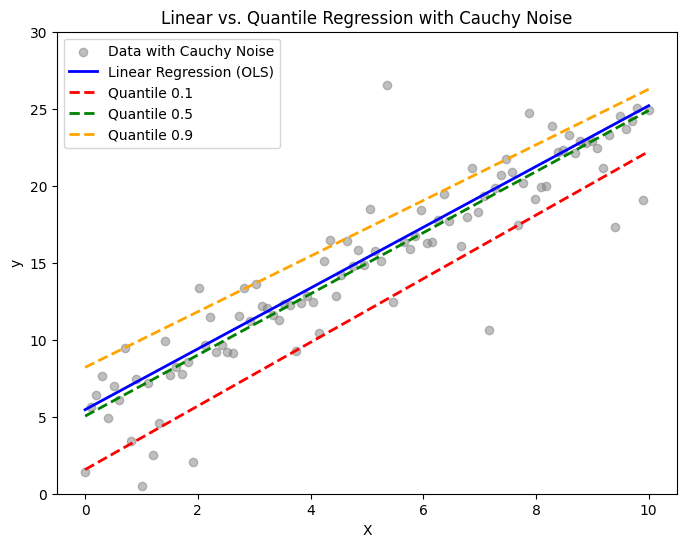

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression

# Set seed for reproducibility
np.random.seed(42)

# Generate synthetic data
n_samples = 100
X = np.linspace(0, 10, n_samples)
true_slope = 2
true_intercept = 5

# Add heavy-tailed Cauchy noise
noise = np.random.standard_cauchy(size=n_samples)  # Cauchy noise
y = true_slope * X + true_intercept + noise

# Reshape for sklearn
X_reshaped = X.reshape(-1, 1)

# Fit Linear Regression (OLS)
ols_model = LinearRegression()
ols_model.fit(X_reshaped, y)
y_pred_ols = ols_model.predict(X_reshaped)

# Fit Quantile Regression (Median, 10th, 90th percentiles)
quantiles = [0.1, 0.5, 0.9]
quantile_models = {q: sm.QuantReg(y, sm.add_constant(X)).fit(q=q) for q in quantiles}
y_preds_quantile = {q: quantile_models[q].predict(sm.add_constant(X)) for q in quantiles}

# Plot results
plt.figure(figsize=(8, 6))
plt.scatter(X, y, color='gray', alpha=0.5, label="Data with Cauchy Noise")
plt.plot(X, y_pred_ols, color='blue', linewidth=2, label="Linear Regression (OLS)")

colors = ['red', 'green', 'orange']
for q, color in zip(quantiles, colors):
    plt.plot(X, y_preds_quantile[q], color=color, linewidth=2, linestyle='--', label=f"Quantile {q}")

plt.xlabel("X")
plt.ylabel("y")
plt.ylim(0, 30)
plt.legend()
plt.title("Linear vs. Quantile Regression with Cauchy Noise")
plt.show()
